In [2]:
!pip install -q sentence-transformers

Loading Sentence Transformer

In [3]:
from sentence_transformers import SentenceTransformer

# Load pretrained sentence embedding model
model = SentenceTransformer("all-MiniLM-L6-v2")

print("Model loaded successfully!")
print("Embedding dimension:", model.get_sentence_embedding_dimension())

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Model loaded successfully!
Embedding dimension: 384


/tmp/ipykernel_575/2514469654.py:7: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embedding dimension:", model.get_sentence_embedding_dimension())


Downloads a pretrained model (if not already cached).



Loads it into memory.



Each sentence will be converted into a vector containing 384 numerical values.

Creating 10 healthcare sentences

In [4]:
sentences = [
    "Patients should attend their scheduled medical appointments.",
    "People must visit the hospital for regular health checkups.",
    "Diabetes patients should monitor their blood sugar levels regularly.",
    "High blood glucose can indicate a risk of diabetes.",
    "Doctors prescribe antibiotics to treat bacterial infections.",
    "Antibiotics are medicines used against bacterial diseases.",
    "Regular exercise helps improve cardiovascular health.",
    "Physical activity strengthens the heart and improves fitness.",
    "Vaccination helps protect people from infectious diseases.",
    "Washing hands regularly helps prevent the spread of infections."
]

print("Total sentences:", len(sentences))

for i, sentence in enumerate(sentences, 1):
    print(f"{i}. {sentence}")

Total sentences: 10
1. Patients should attend their scheduled medical appointments.
2. People must visit the hospital for regular health checkups.
3. Diabetes patients should monitor their blood sugar levels regularly.
4. High blood glucose can indicate a risk of diabetes.
5. Doctors prescribe antibiotics to treat bacterial infections.
6. Antibiotics are medicines used against bacterial diseases.
7. Regular exercise helps improve cardiovascular health.
8. Physical activity strengthens the heart and improves fitness.
9. Vaccination helps protect people from infectious diseases.
10. Washing hands regularly helps prevent the spread of infections.


Some sentences have similar meanings but different wording. Others share words but have different meanings. This helps us test whether embeddings understand meaning rather than just matching words.

Generating embeddings

In [5]:
import torch

# Convert sentences into embeddings
embeddings = model.encode(
    sentences,
    convert_to_tensor=True
)

print("Embedding shape:", embeddings.shape)
print("\nFirst sentence embedding (first 10 values):")
print(embeddings[0][:10])

Embedding shape: torch.Size([10, 384])

First sentence embedding (first 10 values):
tensor([-0.0197,  0.0826, -0.0053, -0.0258, -0.1150,  0.0177,  0.0226,  0.0309,
         0.0349, -0.0419], device='cuda:0')


10 = number of sentences.



384 = numerical values representing each sentence's meaning.



Each sentence gets its own vector.

Calculate cosine similarity


Cosine similarity measures how close two vectors are in direction.

In [6]:
from sentence_transformers import util
import pandas as pd

# Calculate pairwise cosine similarity
similarity_matrix = util.cos_sim(embeddings, embeddings)

# Convert to NumPy for visualization
similarity_scores = similarity_matrix.cpu().numpy()

# Display as a table
similarity_df = pd.DataFrame(
    similarity_scores,
    index=[f"S{i+1}" for i in range(10)],
    columns=[f"S{i+1}" for i in range(10)]
)

similarity_df.round(3)

,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10
S1,1.000,0.626,0.399,0.102,0.405,0.196,0.202,0.100,0.191,0.187
S2,0.626,1.000,0.381,0.140,0.277,0.155,0.238,0.175,0.227,0.209
S3,0.399,0.381,1.000,0.594,0.130,0.035,0.292,0.140,0.142,0.089
S4,0.102,0.140,0.594,1.000,-0.071,-0.013,0.162,0.086,0.091,-0.005
S5,0.405,0.277,0.130,-0.071,1.000,0.784,0.065,-0.032,0.326,0.403
S6,0.196,0.155,0.035,-0.013,0.784,1.000,0.067,0.030,0.314,0.345
S7,0.202,0.238,0.292,0.162,0.065,0.067,1.000,0.764,0.175,0.124
S8,0.100,0.175,0.140,0.086,-0.032,0.030,0.764,1.000,0.223,0.059
S9,0.191,0.227,0.142,0.091,0.326,0.314,0.175,0.223,1.000,0.456
S10,0.187,0.209,0.089,-0.005,0.403,0.345,0.124,0.059,0.456,1.000


Expected: A 10 × 10 matrix with similarity scores.
- Close to 1: highly similar meanings.
- Around 0: weak similarity.
- Negative: opposite vector directions.

Visualize the similarity matrix

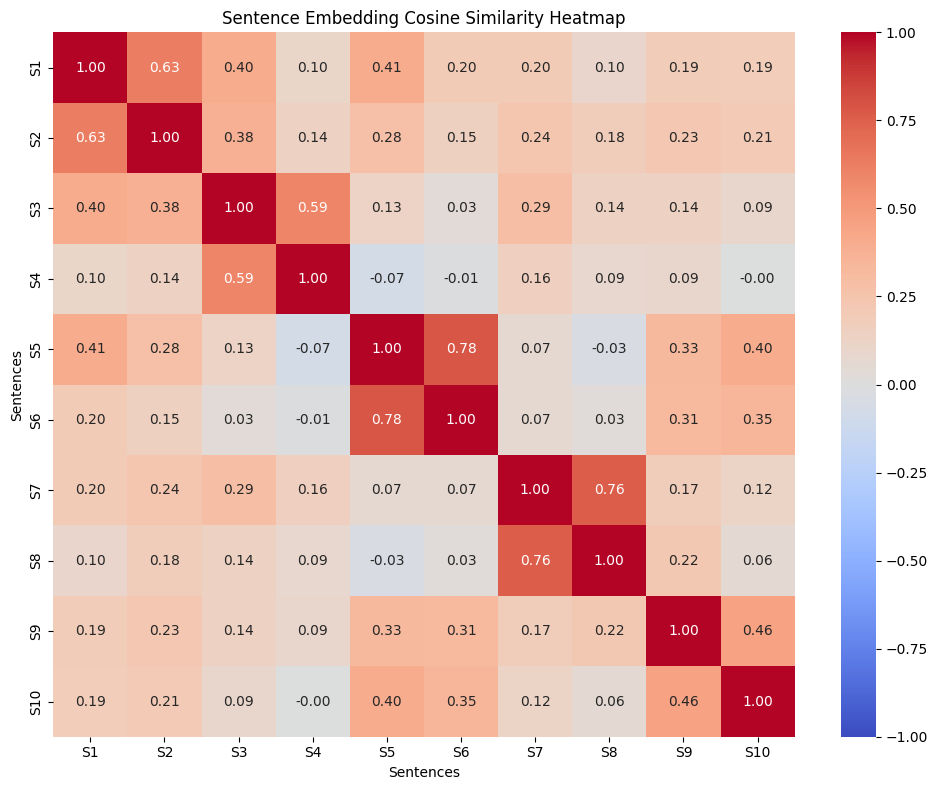

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    similarity_scores,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    xticklabels=[f"S{i+1}" for i in range(10)],
    yticklabels=[f"S{i+1}" for i in range(10)],
    vmin=-1,
    vmax=1
)

plt.title("Sentence Embedding Cosine Similarity Heatmap")
plt.xlabel("Sentences")
plt.ylabel("Sentences")
plt.tight_layout()
plt.show()

The strongest pair is S7 and S8 (0.764):
- S7: Regular exercise helps improve cardiovascular health.
- S8: Physical activity strengthens the heart and improves fitness.

They share no exact words, yet the similarity is high. This demonstrates semantic understanding.

Finding a semantic similarity failure

In [8]:
test_pairs = [
    (
        "The patient was admitted to the hospital.",
        "The patient was discharged from the hospital."
    ),
    (
        "The doctor approved the medication.",
        "The doctor rejected the medication."
    ),
    (
        "The patient has high blood pressure.",
        "The patient has low blood pressure."
    )
]

for sentence_a, sentence_b in test_pairs:
    pair_embeddings = model.encode(
        [sentence_a, sentence_b],
        convert_to_tensor=True
    )

    score = util.cos_sim(
        pair_embeddings[0],
        pair_embeddings[1]
    ).item()

    print(f"\nSentence 1: {sentence_a}")
    print(f"Sentence 2: {sentence_b}")
    print(f"Similarity: {score:.3f}")


Sentence 1: The patient was admitted to the hospital.
Sentence 2: The patient was discharged from the hospital.
Similarity: 0.714

Sentence 1: The doctor approved the medication.
Sentence 2: The doctor rejected the medication.
Similarity: 0.779

Sentence 1: The patient has high blood pressure.
Sentence 2: The patient has low blood pressure.
Similarity: 0.857


### Semantic Similarity Failure Analysis

I tested three pairs of healthcare sentences containing similar words but different or opposite meanings.

| Sentence Pair | Similarity |
|---|---:|
| Admitted vs Discharged | 0.714 |
| Approved vs Rejected | 0.779 |
| High vs Low Blood Pressure | 0.857 |

**Identified Failure:**

"The patient has high blood pressure" and
"The patient has low blood pressure" received a similarity score of 0.857.

Although these sentences describe different health conditions, the model assigned a high similarity score because they share many words and similar context.

**Conclusion:**

Sentence embeddings can capture general semantic relationships, but they may struggle with opposite words and fine-grained differences in meaning. Therefore, similarity scores should not always be treated as proof that two sentences have identical meanings.

Building semantic search

In [9]:
from sentence_transformers import util

query = "How can someone prevent getting an infection?"

# Convert query into an embedding
query_embedding = model.encode(
    query,
    convert_to_tensor=True
)

# Find top 3 semantically similar sentences
hits = util.semantic_search(
    query_embedding,
    embeddings,
    top_k=3
)

print("Query:", query)
print("\nTop 3 Results:\n")

for rank, hit in enumerate(hits[0], 1):
    print(f"Rank {rank}")
    print("Similarity:", round(hit["score"], 3))
    print("Sentence:", sentences[hit["corpus_id"]])
    print()

Query: How can someone prevent getting an infection?

Top 3 Results:

Rank 1
Similarity: 0.56
Sentence: Doctors prescribe antibiotics to treat bacterial infections.

Rank 2
Similarity: 0.523
Sentence: Washing hands regularly helps prevent the spread of infections.

Rank 3
Similarity: 0.522
Sentence: Vaccination helps protect people from infectious diseases.



### Semantic Search

I implemented semantic search using cosine similarity and the pretrained sentence embedding model.

**Query:** How can someone prevent getting an infection?

**Top 3 Results:**
1. Doctors prescribe antibiotics to treat bacterial infections. (0.560)
2. Washing hands regularly helps prevent the spread of infections. (0.523)
3. Vaccination helps protect people from infectious diseases. (0.522)

**Observation:**

The search successfully retrieved healthcare-related sentences based on meaning rather than exact keyword matching.

However, the first result was less relevant to the query than the second and third results. This demonstrates that semantic similarity alone does not guarantee perfect retrieval relevance.

RNN, Attention and Transformers

1. Why does an RNN struggle with a long sentence?

An RNN (Recurrent Neural Network) processes a sentence one word at a time. It passes information from one step to the next using a hidden state. When sentences become longer, information from earlier words may gradually be lost. This makes it difficult for an RNN to remember long-term dependencies and understand relationships between distant words.

Example: In a long sentence, the model may struggle to connect a subject at the beginning with a related word near the end.

2. What does Attention allow a model to do?

Attention allows a model to focus on the most relevant words in a sentence while processing a particular word. Instead of depending only on previously stored information, it can give different importance (weights) to different words based on their relevance.

Example: In the sentence "The animal was tired because it had travelled a long distance", attention helps the model relate "it" to "animal".

3. What is Self-Attention?

Self-attention is a mechanism that allows each word in a sentence to examine and understand its relationship with every other word in the same sentence. It calculates attention scores to determine which words are important for understanding the current word.

Example: In "The doctor treated the patient because he was sick", self-attention helps the model understand relationships between words such as "he", "doctor" and "patient" using the surrounding context.


4. Why can Transformers be trained in parallel while RNNs cannot?

RNNs process words sequentially, meaning they must complete one time step before processing the next. Therefore, their training cannot fully parallelize across the sequence.

Transformers use self-attention to process relationships between all input tokens simultaneously. This allows multiple tokens to be processed in parallel during training, making Transformers faster and more efficient to train on large datasets.

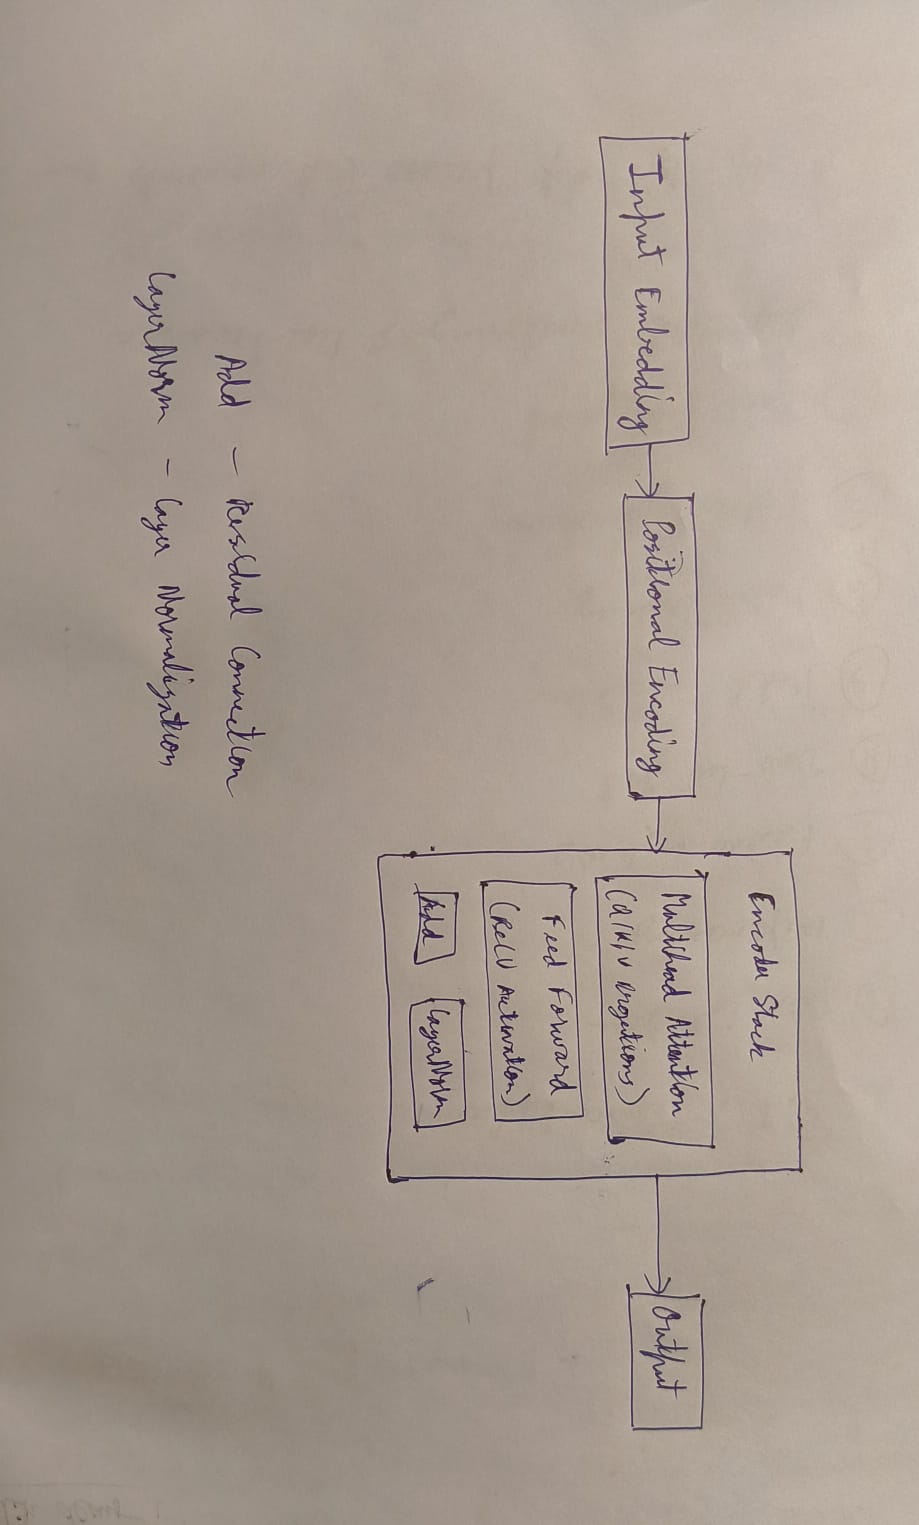

Transformers process all tokens in parallel and therefore do not naturally understand the order of words in a sentence. Positional encoding adds information about each token's position so the model can understand the sequence and word order.